# Airline Review Analysis - Notebook 4: Sentiment Classification

Task: predict whether a passenger **recommends** the airline (yes / no) using only the text of the review.

This is a text classification problem (Unit 3). I compare three approaches:
1. **VADER**: a ready-made sentiment dictionary (an affective lexicon), no training needed
2. **Naive Bayes**: a classic probability based text classifier
3. **Logistic Regression**: a classifier that learns a weight for every word

Input: `data/reviews_preprocessed.csv`
Output: a trained model in `models/` and the train/test split in `data/`

## 1. Loading the data and splitting it

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import joblib
import os

from nltk.sentiment.vader import SentimentIntensityAnalyzer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

sns.set_style("whitegrid")
df = pd.read_csv("data/reviews_preprocessed.csv", parse_dates=["review_date"])
print(df.shape)

(64331, 25)


To test a model fairly, it must be tested on reviews it has never seen. I split the reviews into 80% for training and 20% for testing. `stratify` keeps the same share of yes / no reviews in both parts, and `random_state` makes the split the same every time.

In [2]:
y = df["recommended_bin"]

train_text, test_text, y_train, y_test = train_test_split(
    df["review_text"], y, test_size=0.2, random_state=42, stratify=y)

print("training reviews:", len(train_text), "| recommended:", round(y_train.mean() * 100, 1), "%")
print("testing reviews :", len(test_text), "| recommended:", round(y_test.mean() * 100, 1), "%")

training reviews: 51464 | recommended: 38.3 %
testing reviews : 12867 | recommended: 38.3 %


## 2. Method 1: VADER

VADER has a dictionary of words with sentiment scores (for example "excellent" is positive and "terrible" is negative). For each text it gives a `compound` score from -1 (very negative) to +1 (very positive). I predict "recommended" when the score is at least 0.05, which is the usual rule for VADER.

In [3]:
nltk.download("vader_lexicon", quiet=True)
sia = SentimentIntensityAnalyzer()

print(sia.polarity_scores("The crew were amazing and the seats were comfortable"))
print(sia.polarity_scores("The flight was delayed and nobody helped us"))

{'neg': 0.0, 'neu': 0.496, 'pos': 0.504, 'compound': 0.7964}
{'neg': 0.213, 'neu': 0.787, 'pos': 0.0, 'compound': -0.2263}


In [4]:
# score every review (takes 1-3 minutes)
df["vader"] = df["review_text"].apply(lambda t: sia.polarity_scores(t)["compound"])

vader_train = df.loc[train_text.index, "vader"]
vader_test = df.loc[test_text.index, "vader"]

vader_pred = (vader_test >= 0.05).astype(int)
print("VADER accuracy with threshold 0.05:", round(accuracy_score(y_test, vader_pred), 3))

VADER accuracy with threshold 0.05: 0.803


VADER was made for short texts like tweets, while airline reviews are long and often mix good and bad points. Maybe a different threshold works better. I try a few on the **training** data (never on the test data, otherwise the test would not be fair).

In [5]:
train_acc = {}
for t in [0.05, 0.3, 0.5, 0.7, 0.9]:
    pred = (vader_train >= t).astype(int)
    train_acc[t] = accuracy_score(y_train, pred)
    print("threshold", t, "-> training accuracy", round(train_acc[t], 3))

best_threshold = max(train_acc, key=train_acc.get)
print("best threshold:", best_threshold)

threshold 0.05 -> training accuracy 0.8
threshold 0.3 -> training accuracy 0.822
threshold 0.5 -> training accuracy 0.834
threshold 0.7 -> training accuracy 0.841
threshold 0.9 -> training accuracy 0.803
best threshold: 0.7


In [6]:
vader_pred_tuned = (vader_test >= best_threshold).astype(int)
print("VADER accuracy on test data with threshold", best_threshold, ":", round(accuracy_score(y_test, vader_pred_tuned), 3))

VADER accuracy on test data with threshold 0.7 : 0.848


With a higher threshold VADER improves from about 80% to about 85% accuracy, but it is still not very good. Its dictionary is general (it does not know that "delayed" or "cancelled" are bad), and long airline reviews mix positive and negative words.

## 3. TF-IDF: turning text into numbers

Naive Bayes and Logistic Regression need numbers, not words. **TF-IDF** gives every word in a review a score:
- TF (term frequency): how often the word appears in this review
- IDF (inverse document frequency): lower for words that appear in almost every review (like "flight") and higher for rare, specific words (like "refund")

I use single words and pairs of words (`ngram_range=(1, 2)`), so that "not recommend" and "customer service" are also features. Words that appear in fewer than 5 reviews are ignored. The vectorizer is fitted on the training reviews only.

In [7]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_df=0.9, sublinear_tf=True)

X_train = tfidf.fit_transform(train_text)
X_test = tfidf.transform(test_text)

print("matrix shape (reviews x features):", X_train.shape)

matrix shape (reviews x features): (51464, 150977)


## 4. Method 2: Naive Bayes

Naive Bayes uses Bayes' rule to calculate how likely a review belongs to each class given the words it contains. It is called "naive" because it assumes the words are independent of each other. It is very fast.

It has one setting, `alpha` (smoothing, so unseen words do not give zero probability). I try a few values on a small validation part taken from the training data.

In [8]:
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=1, stratify=y_train)

nb_acc = {}
for alpha in [0.05, 0.1, 0.5, 1.0]:
    nb_try = MultinomialNB(alpha=alpha).fit(X_fit, y_fit)
    nb_acc[alpha] = accuracy_score(y_val, nb_try.predict(X_val))
    print("alpha", alpha, "-> validation accuracy", round(nb_acc[alpha], 3))

best_alpha = max(nb_acc, key=nb_acc.get)
print("best alpha:", best_alpha)

alpha 0.05 -> validation accuracy 0.888
alpha 0.1 -> validation accuracy 0.887
alpha 0.5 -> validation accuracy 0.887
alpha 1.0 -> validation accuracy 0.889
best alpha: 1.0


In [9]:
nb = MultinomialNB(alpha=best_alpha).fit(X_train, y_train)
nb_pred = nb.predict(X_test)
print("Naive Bayes accuracy on test data:", round(accuracy_score(y_test, nb_pred), 3))

Naive Bayes accuracy on test data: 0.892


## 5. Method 3: Logistic Regression

Logistic Regression learns a weight for every feature: a positive weight pushes a review toward "recommended" and a negative weight pushes it toward "not recommended". The setting `C` controls how strongly the model avoids over-fitting. `class_weight="balanced"` gives the smaller class (recommended) a bit more importance.

In [10]:
lr_acc = {}
for C in [1, 3, 10]:
    lr_try = LogisticRegression(C=C, max_iter=1000, class_weight="balanced").fit(X_fit, y_fit)
    lr_acc[C] = accuracy_score(y_val, lr_try.predict(X_val))
    print("C", C, "-> validation accuracy", round(lr_acc[C], 3))

best_C = max(lr_acc, key=lr_acc.get)
print("best C:", best_C)

C 1 -> validation accuracy 0.928
C 3 -> validation accuracy 0.929
C 10 -> validation accuracy 0.928
best C: 3


In [11]:
lr = LogisticRegression(C=best_C, max_iter=1000, class_weight="balanced")
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)
print("Logistic Regression accuracy on test data:", round(accuracy_score(y_test, lr_pred), 3))

Logistic Regression accuracy on test data: 0.935


## 6. Comparing the models

Accuracy alone can hide problems, so I also use:
- **Precision**: of the reviews the model called "recommended", how many really were
- **Recall**: of the reviews that really were "recommended", how many the model found
- **F1 score**: a single number that balances precision and recall

In [12]:
def evaluate(name, pred):
    return {"model": name,
            "accuracy": accuracy_score(y_test, pred),
            "precision": precision_score(y_test, pred),
            "recall": recall_score(y_test, pred),
            "f1": f1_score(y_test, pred)}

results = pd.DataFrame([
    evaluate("VADER (threshold 0.05)", vader_pred),
    evaluate("VADER (tuned threshold)", vader_pred_tuned),
    evaluate("Naive Bayes", nb_pred),
    evaluate("Logistic Regression", lr_pred),
]).round(3)
results

,model,accuracy,precision,recall,f1
0,VADER (threshold 0.05),0.803,0.683,0.904,0.778
1,VADER (tuned threshold),0.848,0.812,0.783,0.797
2,Naive Bayes,0.892,0.863,0.854,0.859
3,Logistic Regression,0.935,0.910,0.922,0.916


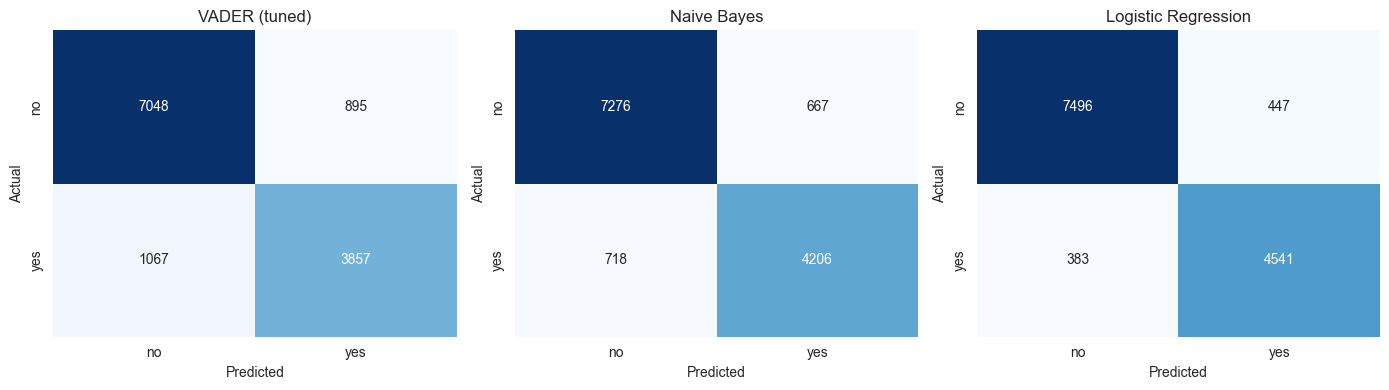

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, pred) in zip(axes, [("VADER (tuned)", vader_pred_tuned), ("Naive Bayes", nb_pred), ("Logistic Regression", lr_pred)]):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["no", "yes"], yticklabels=["no", "yes"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

Logistic Regression is the best model with about 93.5% accuracy and an F1 score of 0.92. Naive Bayes comes second (about 89%) and VADER is last (about 80% to 85%). In the confusion matrices the numbers on the diagonal are correct predictions, and Logistic Regression has the fewest mistakes (447 + 383).

The models that learn from the labelled reviews beat the ready-made dictionary because they learn the vocabulary of airline reviews themselves.

## 7. Which words does the model use?

Because Logistic Regression has one weight per word, I can look at the words with the biggest weights. These weights act like a dictionary of sentiment words that the model **learned from the reviews**, instead of a ready-made dictionary like VADER.

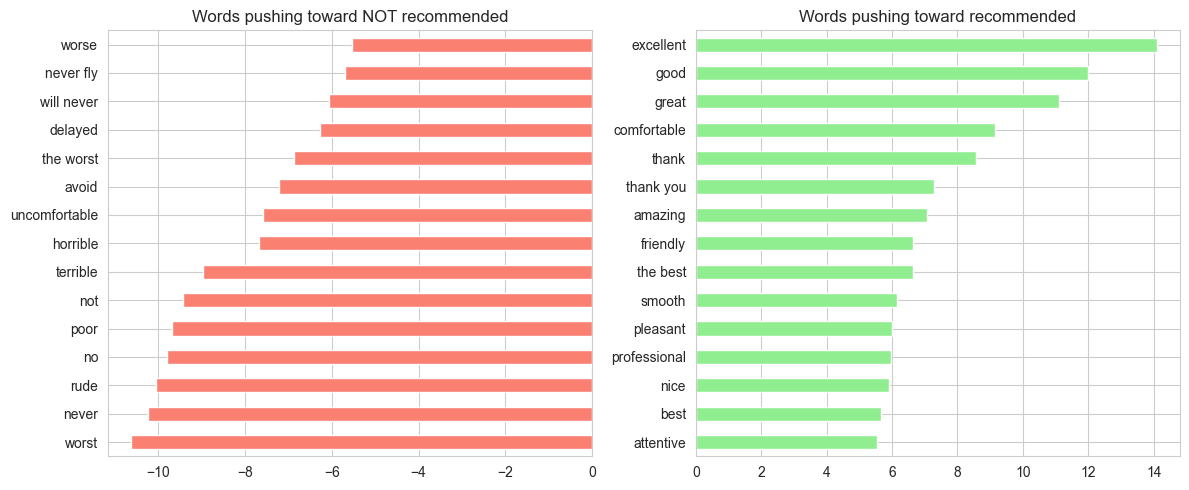

In [14]:
weights = pd.Series(lr.coef_[0], index=tfidf.get_feature_names_out()).sort_values()

top_no = weights.head(15)
top_yes = weights.tail(15)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
top_no.plot(kind="barh", ax=axes[0], color="salmon")
axes[0].set_title("Words pushing toward NOT recommended")
top_yes.plot(kind="barh", ax=axes[1], color="lightgreen")
axes[1].set_title("Words pushing toward recommended")
plt.tight_layout()
plt.show()

The learned words make sense: "worst", "never", "rude", "poor" and "terrible" push toward not recommended, and "excellent", "good", "great" and "comfortable" push toward recommended. "no" and "not" also have strong negative weights, so keeping negation words in Notebook 3 was the right decision.

These weights work like a sentiment dictionary learned from the data. I will use this idea again in Notebook 6 to score individual sentences.

## 8. Does the preprocessing from Notebook 3 help?

I train the same Logistic Regression on the cleaned text (`text_clean`: lemmatized, stopwords removed) and compare it with the raw text.

In [15]:
tfidf_clean = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_df=0.9, sublinear_tf=True)
X_train_clean = tfidf_clean.fit_transform(df.loc[train_text.index, "text_clean"])
X_test_clean = tfidf_clean.transform(df.loc[test_text.index, "text_clean"])

lr_clean = LogisticRegression(C=best_C, max_iter=1000, class_weight="balanced").fit(X_train_clean, y_train)
print("Logistic Regression on raw text  :", round(accuracy_score(y_test, lr_pred), 3))
print("Logistic Regression on text_clean:", round(accuracy_score(y_test, lr_clean.predict(X_test_clean)), 3))

Logistic Regression on raw text  : 0.935
Logistic Regression on text_clean: 0.933


The two results are almost the same (about 93.5% and 93.3%). TF-IDF with word pairs already works well on the raw text, so I use the raw text for the classifier. The cleaned text is still useful for counting words and phrases, as in Notebook 3.

## 9. Looking at the mistakes

I look at test reviews that the Logistic Regression got wrong, starting with the ones where it was most confident.

In [16]:
test_df = df.loc[test_text.index, ["airline", "over_all_rating", "recommended", "review_text"]].copy()
test_df["prob_yes"] = lr.predict_proba(X_test)[:, 1]
test_df["predicted"] = lr_pred
wrong = test_df[test_df["predicted"] != y_test]
print("wrong predictions:", len(wrong), "out of", len(test_df))

print()
print("ACTUALLY recommended, but model said no:")
for _, r in wrong[wrong["recommended"] == "yes"].sort_values("prob_yes").head(3).iterrows():
    print(" - rating", r["over_all_rating"], "|", r["review_text"][:350])

print()
print("ACTUALLY not recommended, but model said yes:")
for _, r in wrong[wrong["recommended"] == "no"].sort_values("prob_yes", ascending=False).head(3).iterrows():
    print(" - rating", r["over_all_rating"], "|", r["review_text"][:350])

wrong predictions: 830 out of 12867

ACTUALLY recommended, but model said no:
 - rating 1.0 | Poor customer service. They focus only on profit not passenger. They cancel my flight without notice or inform me. So I send email requesting refund but until now no refund happen. Its has been a month but still no response for my Refund. I will not recommend this airline anymore.
 - rating 1.0 | The lack of customer caring and the rudeness was appalling. My last name changed when I got married therefore my new passport has my married name. For some reason they would not accept the passport and my marriage certificate as a proof of that. My Indian visa is on my maiden name. I tried to reason with them that the US government takes security s
 - rating 1.0 | Flying business class and they lost my suitcase. Claiming your suitcase and contacting the missing baggage department is handled somewhere in India (call center). Total not capable people who answering like robots. Compensation, never heard 

Some of these "mistakes" look like wrong labels in the data: a review with rating 1 that is marked as recommended, or a review with rating 10 that is marked as not recommended. Let me count how many of the wrong predictions are like this.

In [17]:
contradiction = ((wrong["recommended"] == "yes") & (wrong["over_all_rating"] <= 3)) | \
                ((wrong["recommended"] == "no") & (wrong["over_all_rating"] >= 8))
print("wrong predictions where the label contradicts the rating:", contradiction.sum(), "of", len(wrong))

print()
print("Some other mistakes (rating between 4 and 7):")
middle = wrong[(wrong["over_all_rating"] >= 4) & (wrong["over_all_rating"] <= 7)]
for _, r in middle.sample(3, random_state=3).iterrows():
    print(" - rating", r["over_all_rating"], "| actual:", r["recommended"], "|", r["review_text"][:350])

wrong predictions where the label contradicts the rating: 62 of 830

Some other mistakes (rating between 4 and 7):
 - rating 5.0 | actual: yes | The flights were comfortable, and price was great, but customer service needs more coordination. My booked flights had a 4.5 hour layover in MEX in each direction. Two days before my return flights, I received an email saying that the leg from MEX to SCL that was going to depart at 11:55pm was delayed until 5:30am the following morning. I called cu
 - rating 7.0 | actual: yes | We enjoyed not being squashed into a budget airline. We looked forward to our meals but my wife found the choice of a spicy chicken curry or fish to not be much of a choice. She chose the chicken and found it too hot to be edible. Surely on a route that has many non Malaysians flying on it a non spicy non fish meal could be offered. I ordered a veg
 - rating 5.0 | actual: no | I was excited recently to fly on the much lauded Dreamliner! The food was tasty and enjoyable,

Only a small part of the mistakes (62 of 830) are cases where the label contradicts the rating, so for those the model is probably right and the label is wrong. Most of the other mistakes are mixed reviews that praise some things and complain about others, for example the reviews with a rating of 5 or 7 above. One yes / no answer for the whole review cannot capture this, which is the reason for the aspect based analysis in the next notebooks.

## 10. Trying the model on new sentences

In [18]:
def predict_review(text):
    prob = lr.predict_proba(tfidf.transform([text]))[0][1]
    return round(prob, 2)

examples = [
    "The cabin crew were friendly and the flight was on time. Would fly again.",
    "Flight delayed by five hours and nobody told us anything. Never again.",
    "The crew were lovely but the flight was delayed for five hours and we got no information.",
]
for e in examples:
    print(predict_review(e), "<-", e)

1.0 <- The cabin crew were friendly and the flight was on time. Would fly again.
0.01 <- Flight delayed by five hours and nobody told us anything. Never again.
0.73 <- The crew were lovely but the flight was delayed for five hours and we got no information.


The first two sentences are clear and get extreme scores. The third one mixes praise for the crew with a complaint about a delay, and the model gives it 0.73, which means it is unsure and follows the positive words more. A single score does not show which part the passenger is unhappy about. Next I score each topic (crew, delay, food and so on) separately.

## 11. Saving the model and the split

In [19]:
os.makedirs("models", exist_ok=True)
joblib.dump({"tfidf": tfidf, "model": lr}, "models/sentiment_model.joblib")

# remember which reviews were used for training and which for testing
split = pd.DataFrame({"review_id": df.index, "split": "train"})
split.loc[test_text.index, "split"] = "test"
split.to_csv("data/train_test_split.csv", index=False)
print(split["split"].value_counts())

split
train    51464
test     12867
Name: count, dtype: int64


## Summary

- Task: predict "recommended" from the review text, with an 80/20 train/test split.
- VADER reached about 80% accuracy (about 85% after changing the threshold), Naive Bayes about 89%, and Logistic Regression with TF-IDF about 93.5% (F1 = 0.92).
- Models trained on the data beat the general VADER dictionary, because airline reviews have their own vocabulary.
- The learned word weights are sensible and can be used as a sentiment dictionary made from the data.
- Preprocessing (lemmatization, stopword removal) did not improve the classifier, so the raw text is used for classification.
- Mistakes are mostly mixed reviews, which motivates aspect based sentiment analysis.

The trained model is saved in `models/sentiment_model.joblib` and the train/test split in `data/train_test_split.csv`, to be used in the next notebooks.

Next notebook: finding the main topics (aspects) in the reviews using POS tagging and WordNet.